# Character BiLSTM baseline (MODEL 1)

In [11]:
# Run once in the project environment. PyTorch is supplied by the environment.
%pip install -q -r ../requirements.txt


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import json
import os
import re
import sys

import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset
from torch.utils.tensorboard import SummaryWriter
from tqdm.auto import tqdm
import matplotlib.pyplot as plt


sys.path.append('../src')
from evaluate import evaluate, path_baseline, save_preds
from load_data import load_splits

## Configuration

In [13]:
SMOKE = False
OVERFIT = False
SEED = 42
BATCH_SIZE = 256
LR = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 100 if OVERFIT else 1 if SMOKE else 20
EVAL_EVERY = 10 if SMOKE or OVERFIT else 500
PATIENCE = 3
MIN_DELTA = 1e-4


TAG = 'bilstm_overfit' if OVERFIT else 'bilstm_smoke' if SMOKE else 'bilstm'
RESULTS = '../results'
CKPT = f'../models/{TAG}_model1.pt'
LOG = f'{RESULTS}/{TAG}_train_log.csv'
os.makedirs(RESULTS, exist_ok=True)
os.makedirs('../checkpoints', exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('device:', device, '| torch:', torch.__version__)

device: cuda | torch: 2.7.0+cu128


## Load data and character encoding

In [14]:
splits = load_splits()

if SMOKE:
    splits = {
        s: d.sample(2000 if s == 'train' else 500, random_state=SEED)
        for s, d in splits.items()
    }

if OVERFIT:
    splits['train'] = splits['val'] = splits['train'].groupby('label').head(3)

with open('../data/vocab.json') as f:
    vocab = json.load(f)
with open('../data/config.json') as f:
    config = json.load(f)

char_to_idx = {c: i for i, c in enumerate(vocab['index_to_string'])}
PAD_IDX = vocab['pad_idx']
UNK_IDX = vocab['unk_idx']
MAX_LEN = config['max_len']

print({s: len(d) for s, d in splits.items()})
print(f'vocab={len(char_to_idx)}, MAX_LEN={MAX_LEN}, PAD_IDX={PAD_IDX}, UNK_IDX={UNK_IDX}')

for split, data in splits.items():
    print(f'\n{split} sample:')
    display(data.sample(min(5, len(data)), random_state=SEED))


{'train': 185397, 'val': 23175, 'test': 23175}
vocab=67, MAX_LEN=256, PAD_IDX=0, UNK_IDX=1

train sample:


,URL,label
95366,rarerental.com,0
113392,isbn-international.org,1
157444,wpwhitesecurity.com,1
170046,yugatech.com,1
44740,miscotiaenlinepe.eshost.com.ar/?i=1,0



val sample:


,URL,label
8821,off2ce2023.firebaseapp.com,0
247,drive-file-device-local-disk.firebaseapp.com,0
19754,frostdiamonds.com,1
8678,eblaq-irsana.ml,0
18013,pipeliner.com.au,1



test sample:


,URL,label
8821,georgiatheatre.com,1
247,carbonrom.org,1
19754,projet-voltaire.fr,1
8678,alassadgroup.com,0
18013,metasupport1000289375124.web.app,0


In [15]:
class URLDataset(Dataset):
    def __init__(self, df):
        self.urls = df['URL'].tolist()
        self.labels = df['label'].astype('int64').tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        ids = [char_to_idx.get(c, UNK_IDX) for c in self.urls[index][:MAX_LEN]]
        return torch.tensor(ids, dtype=torch.long), self.labels[index]

def collate(batch):
    ids, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in ids], dtype=torch.long)
    ids = pad_sequence(ids, batch_first=True, padding_value=PAD_IDX)
    return ids, lengths, torch.tensor(labels, dtype=torch.long)

datasets = {s: URLDataset(df) for s, df in splits.items()}
train_loader = DataLoader(datasets['train'], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(datasets['val'], batch_size=512, shuffle=False, collate_fn=collate)
test_loader = DataLoader(datasets['test'], batch_size=512, shuffle=False, collate_fn=collate)
ids, lengths, labels = next(iter(train_loader))
print('input:', tuple(ids.shape), '| lengths:', tuple(lengths.shape), '| labels:', tuple(labels.shape))

input: (256, 235) | lengths: (256,) | labels: (256,)


## BiLSTM model

The embedding maps characters to vectors. Packing prevents padding from being processed. The final forward and backward hidden states are concatenated, then classified with two logits. Since the dataset labels are unchanged, class 0 is phishing and `softmax(logits)[:, 0]` is `p_phish`.

In [16]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=256, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, ids, lengths):
        embedded = self.embedding(ids)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        representation = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(representation))

model = BiLSTMClassifier(len(char_to_idx)).to(device)
with torch.no_grad():
    print('model output:', tuple(model(ids.to(device), lengths.to(device)).shape))
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')

model output: (256, 2)
parameters: 2,241,730


In [17]:
# Hyperparameter tuning. Set TUNE = True to run it.
# Configuration 3 performed best, set parameters accordingly for final training.
TUNE = False
TUNE_EPOCHS = 2
TUNE_MAX_TRAIN_ROWS = 20000  # use None to tune on all training URLs
TUNE_CANDIDATES = [
    {"lr": 5e-4, "embedding_dim": 64, "hidden_dim": 128, "num_layers": 2, "dropout": 0.3, "batch_size": 256},
    {"lr": 1e-3, "embedding_dim": 64, "hidden_dim": 128, "num_layers": 2, "dropout": 0.3, "batch_size": 256},
    {"lr": 1e-3, "embedding_dim": 64, "hidden_dim": 256, "num_layers": 2, "dropout": 0.3, "batch_size": 256},
    {"lr": 1e-3, "embedding_dim": 64, "hidden_dim": 128, "num_layers": 2, "dropout": 0.5, "batch_size": 256},
]


def score_tuning_model(candidate_model, loader, labels):
    candidate_model.eval()
    probabilities = []
    with torch.no_grad():
        for ids, lengths, _ in loader:
            ids, lengths = ids.to(device), lengths.to(device)
            logits = candidate_model(ids, lengths)
            probabilities.append(torch.softmax(logits, dim=-1)[:, 0].cpu())
    return evaluate(labels, torch.cat(probabilities).numpy())


if TUNE:
    tune_df = splits["train"]
    if TUNE_MAX_TRAIN_ROWS is not None:
        tune_df = tune_df.sample(TUNE_MAX_TRAIN_ROWS, random_state=SEED)
    tune_dataset = URLDataset(tune_df)
    tune_loss_fn = nn.CrossEntropyLoss()
    tune_results = []

    for candidate_number, candidate in enumerate(TUNE_CANDIDATES, start=1):
        candidate_loader = DataLoader(
            tune_dataset,
            batch_size=candidate["batch_size"],
            shuffle=True,
            collate_fn=collate,
        )
        candidate_model = BiLSTMClassifier(
            len(char_to_idx),
            embedding_dim=candidate["embedding_dim"],
            hidden_dim=candidate["hidden_dim"],
            num_layers=candidate["num_layers"],
            dropout=candidate["dropout"],
        ).to(device)
        candidate_optimizer = torch.optim.AdamW(
            candidate_model.parameters(),
            lr=candidate["lr"],
            weight_decay=WEIGHT_DECAY,
        )

        for _ in range(TUNE_EPOCHS):
            candidate_model.train()
            for ids, lengths, labels in candidate_loader:
                ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
                candidate_optimizer.zero_grad()
                loss = tune_loss_fn(candidate_model(ids, lengths), labels)
                loss.backward()
                nn.utils.clip_grad_norm_(candidate_model.parameters(), 1.0)
                candidate_optimizer.step()

        metrics = score_tuning_model(candidate_model, val_loader, splits["val"].label)
        tune_results.append({**candidate, "val_f1": metrics["f1"], "val_recall": metrics["recall"]})
        print(f"candidate {candidate_number}: val f1={metrics['f1']:.4f}")
        del candidate_model, candidate_optimizer

    tuning_results = pd.DataFrame(tune_results).sort_values("val_f1", ascending=False)
    best_config = tuning_results.iloc[0].to_dict()
    display(tuning_results)
else:
    best_config = {
        "lr": LR,
        "embedding_dim": 64,
        "hidden_dim": 128,
        "num_layers": 2,
        "dropout": 0.3,
        "batch_size": BATCH_SIZE,
    }

LR = float(best_config["lr"])
BATCH_SIZE = int(best_config["batch_size"])
model = BiLSTMClassifier(
    len(char_to_idx),
    embedding_dim=int(best_config["embedding_dim"]),
    hidden_dim=int(best_config["hidden_dim"]),
    num_layers=int(best_config["num_layers"]),
    dropout=float(best_config["dropout"]),
).to(device)
train_loader = DataLoader(
    datasets["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate,
)
print(f"final clean-training config: lr={LR}, batch_size={BATCH_SIZE}, parameters={sum(p.numel() for p in model.parameters()):,}")

final clean-training config: lr=0.001, batch_size=256, parameters=598,722


## Evaluation helpers

In [18]:
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def run_eval(loader):
    model.eval()
    total_loss, probabilities = 0.0, []
    for ids, lengths, labels in loader:
        ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            logits = model(ids, lengths).float()
        total_loss += loss_fn(logits, labels).item() * len(labels)
        probabilities.append(torch.softmax(logits, dim=-1)[:, 0].cpu())
    return total_loss / len(loader.dataset), torch.cat(probabilities).numpy()

def predict(urls):
    frame = pd.DataFrame({'URL': [str(url).strip() for url in urls], 'label': 1})
    dataset = URLDataset(frame)
    loader = DataLoader(dataset, batch_size=512, shuffle=False, collate_fn=collate)
    return run_eval(loader)[1]


## Training

This uses AdamW, six-percent linear warmup/decay, gradient clipping, validation loss checkpointing, and early stopping. 

In [19]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = MAX_EPOCHS * len(train_loader)
warmup = int(0.06 * total_steps)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: step / max(1, warmup) if step < warmup else max(0.0, (total_steps - step) / max(1, total_steps - warmup)),
)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
writer = SummaryWriter(f'../runs/{TAG}')
log, running = [], []
best_val, bad, step, stopped = float('inf'), 0, 0, False

def validate_and_checkpoint():
    global best_val, bad
    was_training = model.training
    val_loss, p_val = run_eval(val_loader)
    metrics = evaluate(datasets['val'].labels, p_val)
    improved = val_loss < best_val - MIN_DELTA
    if improved:
        best_val, bad = val_loss, 0
        torch.save(model.state_dict(), CKPT)
    else:
        bad += 1
    if was_training:
        model.train()
    return val_loss, metrics, improved

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for ids, lengths, labels in tqdm(train_loader, desc=f'epoch {epoch}'):
        ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            loss = loss_fn(model(ids, lengths), labels)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        step += 1
        running.append(loss.item())
        writer.add_scalar('loss/train_step', loss.item(), step)

        if step % EVAL_EVERY == 0:
            val_loss, metrics, improved = validate_and_checkpoint()
            row = {'step': step, 'epoch': epoch, 'train_loss': np.mean(running), 'val_loss': val_loss,
                   'val_acc': metrics['accuracy'], 'val_recall': metrics['recall'], 'val_f1': metrics['f1'],
                   'lr': scheduler.get_last_lr()[0], 'best': improved}
            log.append(row)
            running = []
            pd.DataFrame(log).to_csv(LOG, index=False)
            writer.add_scalars('loss', {'train': row['train_loss'], 'val': val_loss}, step)
            writer.add_scalar('val/f1', metrics['f1'], step)
            writer.add_scalar('val/recall', metrics['recall'], step)
            writer.add_scalar('lr', row['lr'], step)
            print(f"step {step} | train {row['train_loss']:.4f} | val {val_loss:.4f} | f1 {metrics['f1']:.4f}" + (' | best' if improved else ''))
            if bad >= PATIENCE:
                print(f'early stopping: val loss did not improve for {PATIENCE} evals')
                stopped = True
                break
    if stopped:
        break
    if step % EVAL_EVERY != 0:
        val_loss, metrics, improved = validate_and_checkpoint()
        writer.add_scalar('val/f1', metrics['f1'], step)
        writer.add_scalar('val/recall', metrics['recall'], step)
        writer.add_scalar('lr', scheduler.get_last_lr()[0], step)
        print(f"epoch {epoch} | val {val_loss:.4f} | f1 {metrics['f1']:.4f}" + (' | best' if improved else ''))
        if bad >= PATIENCE:
            print(f'early stopping: val loss did not improve for {PATIENCE} evals')
            break
writer.close()
if device.type == 'cuda':
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB "
          f"of {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

/tmp/ipykernel_2178/2814769066.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


epoch 1:   0%|          | 0/725 [00:00<?, ?it/s]

step 500 | train 0.4193 | val 0.2884 | f1 0.8555 | best
epoch 1 | val 0.2826 | f1 0.8562 | best


epoch 2:   0%|          | 0/725 [00:00<?, ?it/s]

step 1000 | train 0.2920 | val 0.2756 | f1 0.8604 | best
epoch 2 | val 0.2727 | f1 0.8663 | best


epoch 3:   0%|          | 0/725 [00:00<?, ?it/s]

... (9 outputs left out)

epoch 8:   0%|          | 0/725 [00:00<?, ?it/s]

step 5500 | train 0.2302 | val 0.2505 | f1 0.8785
epoch 8 | val 0.2491 | f1 0.8810 | best


epoch 9:   0%|          | 0/725 [00:00<?, ?it/s]

step 6000 | train 0.2241 | val 0.2555 | f1 0.8780
step 6500 | train 0.2232 | val 0.2543 | f1 0.8801
epoch 9 | val 0.2537 | f1 0.8787
early stopping: val loss did not improve for 3 evals
peak GPU memory: 0.4 GB of 15.6 GB


## Test evaluation and comparable outputs

In [20]:
if not os.path.exists(CKPT):
    raise FileNotFoundError(f'No checkpoint found at {CKPT}; run the training cell first.')
model.load_state_dict(torch.load(CKPT, map_location=device, weights_only=True))
test = splits['test']
test_loss, p_test = run_eval(test_loader)
test_metrics = evaluate(test['label'], p_test)
save_preds(f'{RESULTS}/{TAG}_test_original.csv', test['URL'], test['label'], p_test)
with open(f'{RESULTS}/{TAG}_test_original.json', 'w') as f:
    json.dump(test_metrics, f, indent=1)

comparison = pd.DataFrame({
    'BiLSTM': test_metrics,
    'path rule': evaluate(test['label'], path_baseline(test['URL'])),
}).drop('confusion_matrix').T
display(comparison.astype(float).round(4))
print('confusion matrix [true phishing, true legitimate]:')
print(np.asarray(test_metrics['confusion_matrix']))

,accuracy,precision,recall,f1,roc_auc,pr_auc
BiLSTM,0.9077,0.9607,0.8125,0.8804,0.9445,0.9486
path rule,0.6210,1.0000,0.0939,0.1716,0.5469,0.4729


confusion matrix [true phishing, true legitimate]:
[[ 7876  1818]
 [  322 13159]]


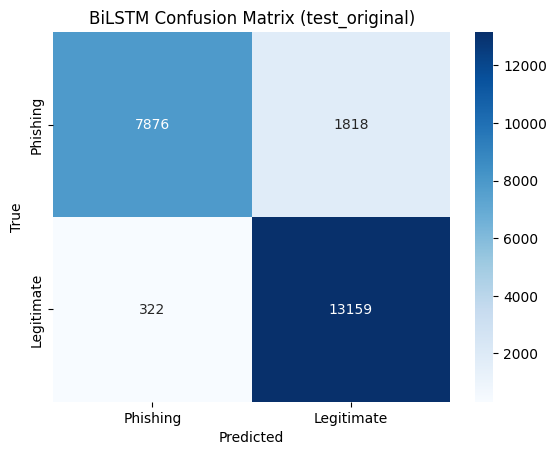

In [21]:
sns.heatmap(
    test_metrics['confusion_matrix'],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Phishing', 'Legitimate'],
    yticklabels=['Phishing', 'Legitimate'],
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('BiLSTM Confusion Matrix (test_original)')
plt.show()

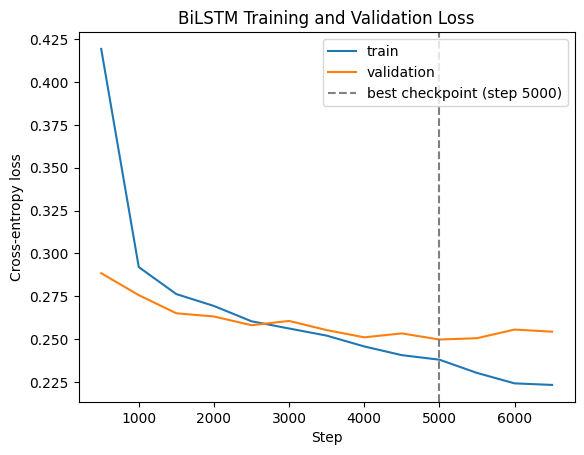

,step,epoch,train_loss,val_loss,val_acc,val_recall,val_f1,lr,best
8,4500,7,0.240609,0.253305,0.905890,0.805653,0.877479,0.000734,False
9,5000,7,0.237969,0.249725,0.907141,0.815556,0.880205,0.000697,True
10,5500,8,0.230249,0.250509,0.906192,0.810604,0.878480,0.000660,False
11,6000,9,0.224145,0.255546,0.905761,0.810914,0.878030,0.000624,False
12,6500,9,0.223236,0.254307,0.906408,0.820920,0.880066,0.000587,False


In [22]:
log_df = pd.read_csv(LOG)
best = log_df.loc[log_df['val_loss'].idxmin()]

plt.plot(log_df['step'], log_df['train_loss'], label='train')
plt.plot(log_df['step'], log_df['val_loss'], label='validation')
plt.axvline(
    best['step'],
    ls='--',
    c='grey',
    label=f"best checkpoint (step {int(best['step'])})",
)
if stopped:
    plt.axvline(
        log_df['step'].iloc[-1],
        ls=':',
        c='red',
        label='early stop',
    )
plt.xlabel('Step')
plt.ylabel('Cross-entropy loss')
plt.title('BiLSTM Training and Validation Loss')
plt.legend()
plt.savefig(f'{RESULTS}/{TAG}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()

display(log_df.tail())